In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [ ]:
columns = [
    'Class', 'Alcohol', 'Malic acid', 'Ash',
    'Alcalinity of ash', 'Magnesium', 'Total phenols',
    'Flavanoids', 'Nonflavanoid phenols',
    'Proanthocyanins', 'Color intensity', 'Hue',
    'OD280/OD315', 'Proline'
]

df = pd.read_csv(
    '/content/wine.data',
    header=None,
    names=columns
)

In [ ]:
df.head().T

,0,1,2,3,4
Class,1.00,1.00,1.00,1.00,1.00
Alcohol,14.23,13.20,13.16,14.37,13.24
Malic acid,1.71,1.78,2.36,1.95,2.59
Ash,2.43,2.14,2.67,2.50,2.87
Alcalinity of ash,15.60,11.20,18.60,16.80,21.00
Magnesium,127.00,100.00,101.00,113.00,118.00
Total phenols,2.80,2.65,2.80,3.85,2.80
Flavanoids,3.06,2.76,3.24,3.49,2.69
Nonflavanoid phenols,0.28,0.26,0.30,0.24,0.39
Proanthocyanins,2.29,1.28,2.81,2.18,1.82


In [ ]:
df.shape

(178, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Class                 178 non-null    int64  
 1   Alcohol               178 non-null    float64
 2   Malic acid            178 non-null    float64
 3   Ash                   178 non-null    float64
 4   Alcalinity of ash     178 non-null    float64
 5   Magnesium             178 non-null    int64  
 6   Total phenols         178 non-null    float64
 7   Flavanoids            178 non-null    float64
 8   Nonflavanoid phenols  178 non-null    float64
 9   Proanthocyanins       178 non-null    float64
 10  Color intensity       178 non-null    float64
 11  Hue                   178 non-null    float64
 12  OD280/OD315           178 non-null    float64
 13  Proline               178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [ ]:
df.describe()

,Class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,1.938202,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.775035,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,1.000000,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,1.000000,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,2.000000,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,3.000000,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,3.000000,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [ ]:
df.isnull().sum()

,0
Class,0
Alcohol,0
Malic acid,0
Ash,0
Alcalinity of ash,0
Magnesium,0
Total phenols,0
Flavanoids,0
Nonflavanoid phenols,0
Proanthocyanins,0


In [ ]:
df['Class'].value_counts().sort_index()

,count
Class,
1,59
2,71
3,48


In [ ]:
X = df.drop('Class', axis=1)
y = df['Class']

In [ ]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (178, 13)
Target shape: (178,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training features: (142, 13)
Testing features: (36, 13)

Training class distribution:
Class
1    47
2    57
3    38
Name: count, dtype: int64

Testing class distribution:
Class
1    12
2    14
3    10
Name: count, dtype: int64


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nTraining feature means (approximately 0):")
print(np.round(X_train_scaled.mean(axis=0), 2))

Training shape: (142, 13)
Testing shape: (36, 13)

Training feature means (approximately 0):
[ 0.  0. -0.  0.  0. -0. -0. -0.  0.  0. -0. -0. -0.]


In [ ]:
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [ ]:
print("Original training shape:", X_train_scaled.shape)
print("PCA training shape:", X_train_pca.shape)

print("Original testing shape:", X_test_scaled.shape)
print("PCA testing shape:", X_test_pca.shape)

Original training shape: (142, 13)
PCA training shape: (142, 2)
Original testing shape: (36, 13)
PCA testing shape: (36, 2)


In [ ]:
print("Explained variance ratio:", pca.explained_variance_ratio_)

print(
    "Total variance retained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Explained variance ratio: [0.35792104 0.19270671]
Total variance retained: 55.06 %


In [ ]:
rf_original = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_original.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
y_pred_original = rf_original.predict(X_test_scaled)

accuracy_original = accuracy_score(y_test, y_pred_original)

print("Random Forest Accuracy (13 features):",
      round(accuracy_original * 100, 2), "%")

Random Forest Accuracy (13 features): 100.0 %


In [ ]:
rf_pca = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_pca.fit(X_train_pca, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
y_pred_pca = rf_pca.predict(X_test_pca)

accuracy_pca = accuracy_score(y_test, y_pred_pca)

print("Random Forest Accuracy (2 PCA components):",
      round(accuracy_pca * 100, 2), "%")

Random Forest Accuracy (2 PCA components): 88.89 %


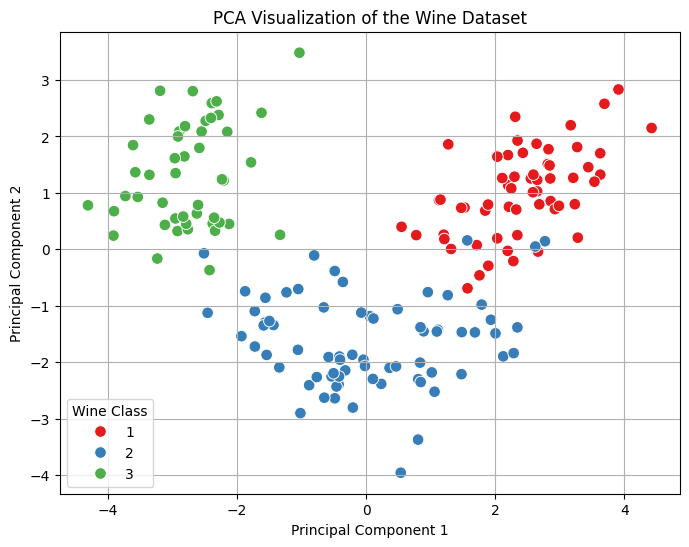

In [ ]:
X_scaled_all = scaler.transform(X)
X_pca_all = pca.transform(X_scaled_all)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca_all[:, 0],
    y=X_pca_all[:, 1],
    hue=y,
    palette='Set1',
    s=70
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Visualization of the Wine Dataset')
plt.legend(title='Wine Class')
plt.grid(True)
plt.show()

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Random Forest (Original)',
        'Random Forest (PCA)'
    ],
    'Features': [13, 2],
    'Accuracy (%)': [
        accuracy_original * 100,
        accuracy_pca * 100
    ]
})

results['Accuracy (%)'] = results['Accuracy (%)'].round(2)

results

,Model,Features,Accuracy (%)
0,Random Forest (Original),13,100.00
1,Random Forest (PCA),2,88.89
